In [13]:
import cupy as cp
import matplotlib.pyplot as plt

import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})


In [ ]:
q = 4
J_corsivo = 1
J = J_corsivo * 2**((q-1)/2) / cp.sqrt(q)
mu = 0.03
Delta = 1/q

T_in = 0.001
T_out = 0.04
p = 60

M = 500

In [15]:
S = 2**(int(cp.log2(100000))+2)

N_max = S // 4

n = cp.fft.fftfreq(S)*S
dealias_mask = cp.abs(n+0.5) < N_max

freq_shift = cp.exp(-1j * cp.pi * n / S)

def trasf(G_t, beta, phase_shift):
    return cp.fft.fft(G_t * phase_shift) * freq_shift * dealias_mask * beta/S

def antitrasf(G, beta, phase_shift):
    return S/beta * cp.fft.ifft(G / freq_shift) * phase_shift.conj()


def solver(G_LL_t, G_LR_t, G_LL, G_LR, T):
    x = 0.5

    beta = 1/T
    t_values = (cp.arange(S) + 0.5) * beta / S

    omega = 2*cp.pi/beta*(n + 0.5)
    phase_shift = cp.exp(-1j*cp.pi/beta*t_values)

    G_LL_free = 1.0/(1j*omega)

    diff = cp.empty((M), dtype=cp.float64)

    for i in range(M):
        if i>= 2:
            check = diff[i-1]-diff[i-2]
            if check > 0:
                x = x/2.0

        Sigma_LL_t = J**2 *cp.power(G_LL_t, q-1)
        Sigma_LL = trasf(Sigma_LL_t, beta, phase_shift)

        Sigma_LR_t = J**2 *cp.power(G_LR_t, q-1)
        Sigma_LR = trasf(Sigma_LR_t, beta, phase_shift) 

        A = 1j * omega - Sigma_LL
        B = Sigma_LR - 1j*mu
        det = A**2 + B**2

        residue_LL = cp.sum(cp.abs((G_LL - A/det) * dealias_mask)**2)/beta
        residue_LR = cp.sum(cp.abs((G_LR - B/det) * dealias_mask)**2)/beta

        G_LL_new = ((1-x)*G_LL + x * A/det) * dealias_mask
        G_LL_new = 0.5 * (G_LL_new - G_LL_new[::-1])
        Delta_G_LL = (G_LL_new - G_LL_free) * dealias_mask
        
        G_LR_new = ((1-x) * G_LR + x * B/det) * dealias_mask
        G_LR_new = 0.5 * (G_LR_new + G_LR_new[::-1])


        G_LL_new_t = 0.5 + cp.real(antitrasf(Delta_G_LL, beta, phase_shift))
        G_LR_new_t = 1j*cp.imag(antitrasf(G_LR_new, beta, phase_shift))

        diff[i] = (cp.sum(cp.abs(G_LL_new_t-G_LL_t)**2) + cp.sum(cp.abs(G_LR_new_t-G_LR_t)**2))*beta/S

        G_LL, G_LR = G_LL_new, G_LR_new
        G_LL_t, G_LR_t = G_LL_new_t, G_LR_new_t

        if (residue_LL < 1e-15) and (residue_LR < 1e-15):
            break    

    return G_LL_t, G_LR_t, G_LL, G_LR



def compute_F(G_LL_t, G_LR_t, G_LL, G_LR, T):
    beta = 1/T
    F = 0

    t_values = (cp.arange(S) + 0.5) * beta / S

    omega = 2*cp.pi/beta*(n + 0.5)
    phase_shift = cp.exp(-1j*cp.pi/beta*t_values)

    Sigma_LL_t = J**2 *cp.power(G_LL_t, q-1)
    Sigma_LL = trasf(Sigma_LL_t, beta, phase_shift)
    
    Sigma_LR_t = J**2 *cp.power(G_LR_t, q-1)
    Sigma_LR = trasf(Sigma_LR_t, beta, phase_shift)

    p1 = cp.sum(cp.log((1j*omega - Sigma_LL)/(1j*omega)))
    p2 = cp.sum(Sigma_LL*G_LL[::-1])

    F = F + (-T*(cp.log(2) + p1 -(1-1/q)*p2)).real

    p1 = cp.sum(cp.log(1- (Sigma_LR-1j*mu)*(-Sigma_LR[::-1]+1j*mu)/((1j*omega-Sigma_LL)*(1j*omega-Sigma_LL))))
    p2 = cp.sum(Sigma_LR*G_LR[::-1])

    F = F + (-T*( 0.5*p1 -(1-1/q)*p2)).real

    return F






In [16]:
T_range = cp.linspace(T_in, 0.025, p)
T_range = cp.append(T_range, T_out)
Dt = (0.025-T_in)/p
F = cp.empty(2*T_range.size, dtype=cp.float64)

beta = 1/T_out

t_values = (cp.arange(S) + 0.5) * beta / S

omega = 2*cp.pi/beta*(n + 0.5)
phase_shift = cp.exp(-1j*cp.pi/beta*t_values)

G_LL_t = cp.full(t_values.size, 0.5)
G_LL = 1.0/(1j*omega)
G_LL_free = G_LL

cost = 0.0
G_LR_t = cp.full(t_values.size, 1j*cost)
G_LR = 2 * cost / omega



for k in range(T_range.size):

    T = T_range[T_range.size-1-k]

    G_LL_t, G_LR_t, G_LL, G_LR = solver(G_LL_t, G_LR_t, G_LL, G_LR, T)

    F[T_range.size-1-k] = compute_F(G_LL_t, G_LR_t, G_LL, G_LR, T)

    lam = 1 - Dt/T

    if T > 0.03:
         lam = 1 - (T_out-0.025)/T

    # G_LL *= 1.0 / lam
    # G_LR *= 1.0 /lam

    G_LL_t = lam**(2*Delta) * G_LL_t
    G_LR_t = lam**(2*Delta) * G_LR_t
    G_LL = lam**(2*Delta-1) * G_LL
    G_LR = lam**(2*Delta-1) * G_LR

# G_LL *= lam
# G_LR *= lam

G_LL_t = lam**(-2*Delta) * G_LL_t
G_LR_t = lam**(-2*Delta) * G_LR_t
G_LL = lam**(-2*Delta+1) * G_LL
G_LR = lam**(-2*Delta+1) * G_LR


for k in range(T_range.size):
    T = T_range[k]

    G_LL_t, G_LR_t, G_LL, G_LR = solver(G_LL_t, G_LR_t, G_LL, G_LR, T)
    F[T_range.size + k] = compute_F(G_LL_t, G_LR_t, G_LL, G_LR, T)

    lam = 1 - Dt/T

    if T > 0.03:
        lam = 1 - (T_out - 0.025) / T

    # G_LL *= lam
    # G_LR *= lam
     
    G_LL_t = lam**(-2 * Delta) * G_LL_t
    G_LR_t = lam**(-2 * Delta) * G_LR_t
    G_LL = lam**(-2 * Delta + 1) * G_LL
    G_LR = lam**(-2 * Delta + 1) * G_LR





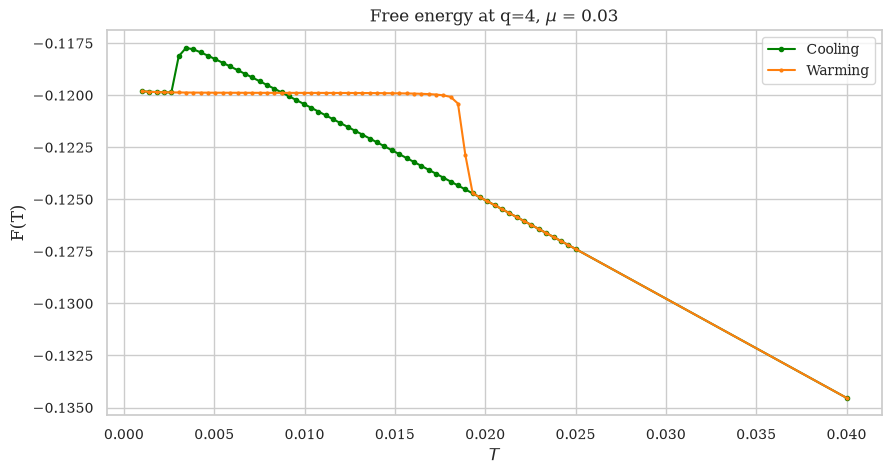

In [17]:
T_range_CPU = T_range.get()
F_CPU = F.get()


plt.figure(figsize=(10, 5))
plt.plot(T_range_CPU, F_CPU[:T_range.size], marker='o', markersize='3', color="green", label="Cooling")
plt.plot(T_range_CPU, F_CPU[T_range.size:], marker='o', markersize='2', color="tab:orange", label="Warming")

plt.xlabel(fr'$T$')
plt.ylabel(fr'F(T)')
plt.title(fr'Free energy at q={q}, $\mu$ = {mu}')
plt.legend()
plt.show()